# Machine Learning CA1 - National Poll on Healthy Aging

In [142]:
import pandas as pd

In [143]:
df = pd.read_csv("NPHA-doctor-visits.csv")

In [144]:
df.head()

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
0,3,2,4,3,3,3,0,0,0,0,1,2,3,1,2
1,2,2,4,2,3,3,1,0,0,1,0,3,3,1,1
2,3,2,3,2,3,3,0,0,0,0,1,3,3,4,1
3,1,2,3,2,3,3,0,0,0,1,0,3,3,4,2
4,3,2,3,3,3,3,1,0,0,0,0,2,3,1,2


In [145]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 15 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   Number of Doctors Visited                   714 non-null    int64
 1   Age                                         714 non-null    int64
 2   Phyiscal Health                             714 non-null    int64
 3   Mental Health                               714 non-null    int64
 4   Dental Health                               714 non-null    int64
 5   Employment                                  714 non-null    int64
 6   Stress Keeps Patient from Sleeping          714 non-null    int64
 7   Medication Keeps Patient from Sleeping      714 non-null    int64
 8   Pain Keeps Patient from Sleeping            714 non-null    int64
 9   Bathroom Needs Keeps Patient from Sleeping  714 non-null    int64
 10  Uknown Keeps Patient from Sleeping    

In [146]:
# Check rows and columns 
df.shape

(714, 15)

In [147]:
#Missing values in each column
df.isna().sum()

Number of Doctors Visited                     0
Age                                           0
Phyiscal Health                               0
Mental Health                                 0
Dental Health                                 0
Employment                                    0
Stress Keeps Patient from Sleeping            0
Medication Keeps Patient from Sleeping        0
Pain Keeps Patient from Sleeping              0
Bathroom Needs Keeps Patient from Sleeping    0
Uknown Keeps Patient from Sleeping            0
Trouble Sleeping                              0
Prescription Sleep Medication                 0
Race                                          0
Gender                                        0
dtype: int64

In [148]:
#Target categorys
df["Number of Doctors Visited"].value_counts()

Number of Doctors Visited
2    372
3    211
1    131
Name: count, dtype: int64

In [149]:
#Display a summary of the columns
df.describe()

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
count,714.000000,714.0,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.000000,714.00000
mean,2.112045,2.0,2.794118,1.988796,3.009804,2.806723,0.247899,0.056022,0.218487,0.504202,0.417367,2.407563,2.829132,1.425770,1.55042
std,0.683441,0.0,0.900939,0.939928,1.361117,0.586582,0.432096,0.230126,0.413510,0.500333,0.493470,0.670349,0.546767,1.003896,0.49780
min,1.000000,2.0,-1.000000,-1.000000,-1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,1.000000,1.00000
25%,2.000000,2.0,2.000000,1.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,3.000000,1.000000,1.00000
50%,2.000000,2.0,3.000000,2.000000,3.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,3.000000,1.000000,2.00000
75%,3.000000,2.0,3.000000,3.000000,4.000000,3.000000,0.000000,0.000000,0.000000,1.000000,1.000000,3.000000,3.000000,1.000000,2.00000
max,3.000000,2.0,5.000000,5.000000,6.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,3.000000,5.000000,2.00000


In [150]:
#Check the distribution of age categories
df["Age"].value_counts()

Age
2    714
Name: count, dtype: int64

In [151]:
#Check the distribution in Mental Health
df["Mental Health"].value_counts()

Mental Health
 2    282
 1    219
 3    167
 4     34
-1     10
 5      2
Name: count, dtype: int64

In [152]:
#Check distribution of categories
df["Dental Health"].value_counts()

Dental Health
 2    215
 3    208
 4    127
 1     66
 6     55
 5     39
-1      4
Name: count, dtype: int64

In [153]:
#Check distirbution of categories
df["Trouble Sleeping"].value_counts()

Trouble Sleeping
 3    359
 2    291
 1     62
-1      2
Name: count, dtype: int64

In [154]:
#Check distirbution of categories
df["Phyiscal Health"].value_counts()

Phyiscal Health
 3    291
 2    239
 4    126
 1     36
 5     21
-1      1
Name: count, dtype: int64

In [155]:
#Check distirbution of categories
df["Prescription Sleep Medication"].value_counts()

Prescription Sleep Medication
 3    639
 1     38
 2     34
-1      3
Name: count, dtype: int64

In [156]:
#Remove the constant Age columns for preserve the original DataFrame
df_clean = df.drop(["Age"], axis=1)

In [157]:
#Check dimensions
df_clean.shape

(714, 14)

In [158]:
#Keep respondents without refused answers 

In [159]:
df_clean = df_clean.loc[df_clean["Phyiscal Health"] != -1]

In [160]:
df_clean = df_clean.loc[df_clean["Mental Health"] != -1]

In [161]:
df_clean = df_clean.loc[df_clean["Dental Health"] != -1]

In [162]:
df_clean = df_clean.loc[df_clean["Trouble Sleeping"] != -1]

In [163]:
df_clean = df_clean.loc[df_clean["Prescription Sleep Medication"] != -1]

In [164]:
#Check how many rows and columns 
df_clean.shape

(696, 14)

In [165]:
#Check the target distribution 
df_clean["Number of Doctors Visited"].value_counts()

Number of Doctors Visited
2    363
3    207
1    126
Name: count, dtype: int64

In [166]:
import matplotlib.pyplot as plt
import seaborn as sns

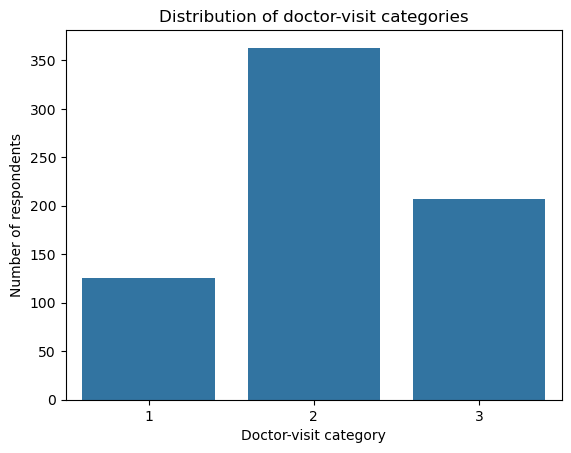

In [186]:
#Graph the target distribution
sns.countplot(x="Number of Doctors Visited", data=df_clean)

plt.title("Distribution of doctor-visit categories")
plt.xlabel("Doctor-visit category")
plt.ylabel("Number of respondents")
plt.show()

In [187]:
X = df_clean.drop(["Number of Doctors Visited", "Dental Health", "Trouble Sleeping"], axis=1)
y = df_clean["Number of Doctors Visited"]

In [188]:
#Check dimensions
X.shape, y.shape

((696, 11), (696,))

In [189]:
#One hot encode 
X = pd.get_dummies(X, columns=["Employment", "Race", "Gender"])

In [190]:
#Check encoded
X.head()

,Phyiscal Health,Mental Health,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Prescription Sleep Medication,Employment_1,Employment_2,Employment_3,Employment_4,Race_1,Race_2,Race_3,Race_4,Race_5,Gender_1,Gender_2
0,4,3,0,0,0,0,1,3,False,False,True,False,True,False,False,False,False,False,True
1,4,2,1,0,0,1,0,3,False,False,True,False,True,False,False,False,False,True,False
2,3,2,0,0,0,0,1,3,False,False,True,False,False,False,False,True,False,True,False
3,3,2,0,0,0,1,0,3,False,False,True,False,False,False,False,True,False,False,True
4,3,3,1,0,0,0,0,3,False,False,True,False,True,False,False,False,False,False,True


In [191]:
#Check dimensions after encoding
X.shape, y.shape

((696, 19), (696,))

In [192]:
df_clean.duplicated().sum()

42

In [193]:
from sklearn.model_selection import train_test_split

In [194]:
#Split the data 5% training and 95% testing
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y, test_size=0.95, random_state=42, stratify=y)

In [195]:
#Check the dimensions of the training and testing
X_train_5.shape, X_test_5.shape, y_train_5.shape, y_test_5.shape

((34, 19), (662, 19), (34,), (662,))

In [196]:
#Split the data, 15% training and 85% testing
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size=0.85, random_state=42, stratify=y)

In [197]:
#Split the data, 25% training and 75% testing
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(X, y, test_size=0.75, random_state=42, stratify=y)

In [198]:
#Compare training and testing dimensions
print("5% training:", X_train_5.shape, "| Testing:", X_test_5.shape)
print("15% training:", X_train_15.shape, "| Testing:", X_test_15.shape)
print("25% training:", X_train_25.shape, "| Testing:", X_test_25.shape)

5% training: (34, 19) | Testing: (662, 19)
15% training: (104, 19) | Testing: (592, 19)
25% training: (174, 19) | Testing: (522, 19)


In [220]:
#Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

In [200]:
#Create the initial about Decision Tree
dt_5 = DecisionTreeClassifier(max_depth=4, random_state=42)

In [201]:
#Train using only the 5% training partition
dt_5.fit(X_train_5, y_train_5)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [202]:
from sklearn.model_selection import cross_val_score

In [203]:
dt_cv_5 = cross_val_score(dt_5, X_train_5, y_train_5, cv=3, scoring="accuracy")

In [205]:
#Display training, and testing results
print("Training accuracy:", dt_5.score(X_train_5, y_train_5))
print("CV accuracy scores:", dt_cv_5)
print("Mean CV accuracy:", dt_cv_5.mean())
print("CV standard deviation:", dt_cv_5.std())
print("Testing accuracy:", dt_5.score(X_test_5, y_test_5))

Training accuracy: 0.6764705882352942
CV accuracy scores: [0.41666667 0.36363636 0.45454545]
Mean CV accuracy: 0.4116161616161616
CV standard deviation: 0.03728490671776111
Testing accuracy: 0.3776435045317221


In [207]:
#Create decision tree for the 15%
dt_15 = DecisionTreeClassifier(max_depth=4, random_state=42)

In [209]:
dt_15.fit(X_train_15, y_train_15)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [214]:
dt_cv_15 = cross_val_score(dt_15, X_train_15, y_train_15, cv=3, scoring="accuracy")

In [215]:
#Display training, and testing results
print("Training accuracy:", dt_15.score(X_train_15, y_train_15))
print("CV accuracy scores:", dt_cv_15)
print("Mean CV accuracy:", dt_cv_15.mean())
print("CV standard deviation:", dt_cv_15.std())
print("Testing accuracy:", dt_15.score(X_test_15, y_test_15))

Training accuracy: 0.625
CV accuracy scores: [0.45714286 0.42857143 0.55882353]
Mean CV accuracy: 0.4815126050420168
CV standard deviation: 0.0558976201212641
Testing accuracy: 0.518581081081081


In [216]:
dt_25 = DecisionTreeClassifier(max_depth=4, random_state=42)

In [217]:
dt_25.fit(X_train_25, y_train_25)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [218]:
dt_cv_25 = cross_val_score(dt_25, X_train_25, y_train_25, cv=3, scoring="accuracy")

In [219]:
#Display training, and testing results
print("Training accuracy:", dt_25.score(X_train_25, y_train_25))
print("CV accuracy scores:", dt_cv_25)
print("Mean CV accuracy:", dt_cv_25.mean())
print("CV standard deviation:", dt_cv_25.std())
print("Testing accuracy:", dt_25.score(X_test_25, y_test_25))

Training accuracy: 0.6379310344827587
CV accuracy scores: [0.51724138 0.36206897 0.48275862]
Mean CV accuracy: 0.4540229885057472
CV standard deviation: 0.06652779829189785
Testing accuracy: 0.49808429118773945


In [221]:
from sklearn.ensemble import RandomForestClassifier

In [222]:
rf_5 = RandomForestClassifier(random_state=42)

In [224]:
rf_5.fit(X_train_5, y_train_5)

RandomForestClassifier(random_state=42)

In [225]:
rf_cv_5 = cross_val_score(rf_5, X_train_5, y_train_5, cv=3, scoring="accuracy")

In [226]:
#Display results
print("Training accuracy:", rf_5.score(X_train_5, y_train_5))
print("CV accuracy scores:", rf_cv_5)
print("Mean CV accuracy:", rf_cv_5.mean())
print("CV standard deviation:", rf_cv_5.std())
print("Testing accuracy:", rf_5.score(X_test_5, y_test_5))

Training accuracy: 0.9705882352941176
CV accuracy scores: [0.41666667 0.54545455 0.63636364]
Mean CV accuracy: 0.5328282828282829
CV standard deviation: 0.09013418332108458
Testing accuracy: 0.4637462235649547


In [228]:
rf_15 = RandomForestClassifier(random_state=42)

In [229]:
rf_15.fit(X_train_15, y_train_15)

RandomForestClassifier(random_state=42)

In [230]:
rf_cv_15 = cross_val_score(rf_15, X_train_15, y_train_15, cv=3, scoring="accuracy")

In [231]:
#Display results
print("Training accuracy:", rf_15.score(X_train_15, y_train_15))
print("CV accuracy scores:", rf_cv_15)
print("Mean CV accuracy:", rf_cv_15.mean())
print("CV standard deviation:", rf_cv_15.std())
print("Testing accuracy:", rf_15.score(X_test_15, y_test_15))

Training accuracy: 0.9230769230769231
CV accuracy scores: [0.31428571 0.37142857 0.47058824]
Mean CV accuracy: 0.38543417366946775
CV standard deviation: 0.06457418054193304
Testing accuracy: 0.4814189189189189


In [232]:
rf_25 = RandomForestClassifier(random_state=42)

In [233]:
rf_25.fit(X_train_25, y_train_25)

RandomForestClassifier(random_state=42)

In [234]:
rf_cv_25 = cross_val_score(rf_25, X_train_25, y_train_25, cv=3, scoring="accuracy")

In [235]:
#Display results
print("Training accuracy:", rf_25.score(X_train_25, y_train_25))
print("CV accuracy scores:", rf_cv_25)
print("Mean CV accuracy:", rf_cv_25.mean())
print("CV standard deviation:", rf_cv_25.std())
print("Testing accuracy:", rf_25.score(X_test_25, y_test_25))

Training accuracy: 0.8850574712643678
CV accuracy scores: [0.46551724 0.44827586 0.4137931 ]
Mean CV accuracy: 0.44252873563218387
CV standard deviation: 0.021503778084907707
Testing accuracy: 0.43486590038314177


In [238]:
#Collection evaluation results
results =[]

In [239]:
#Results Decision Tree
results.append(["Decision Tree", "5%", dt_cv_5.mean(), dt_5.score(X_test_5, y_test_5)])
results.append(["Decision Tree", "15%", dt_cv_15.mean(), dt_15.score(X_test_15, y_test_15)])
results.append(["Decision Tree", "25%", dt_cv_25.mean(), dt_25.score(X_test_25, y_test_25)])

In [240]:
#Results Random Forest
results.append(["Random Forest", "5%", rf_cv_5.mean(), rf_5.score(X_test_5, y_test_5)])
results.append(["Random Forest", "15%", rf_cv_15.mean(), rf_15.score(X_test_15, y_test_15)])
results.append(["Random Forest", "25%", rf_cv_25.mean(), rf_25.score(X_test_25, y_test_25)])

In [247]:
#Create display the comparison table
results_df = pd.DataFrame(results, columns=["Model", "Training proportion", "Mean CV accuracy", "Testing accuracy"])
results_df

,Model,Training proportion,Mean CV accuracy,Testing accuracy
0,Decision Tree,5%,0.481513,0.377644
1,Decision Tree,15%,0.481513,0.518581
2,Decision Tree,25%,0.454023,0.498084
3,Random Forest,5%,0.532828,0.463746
4,Random Forest,15%,0.385434,0.481419
5,Random Forest,25%,0.442529,0.434866


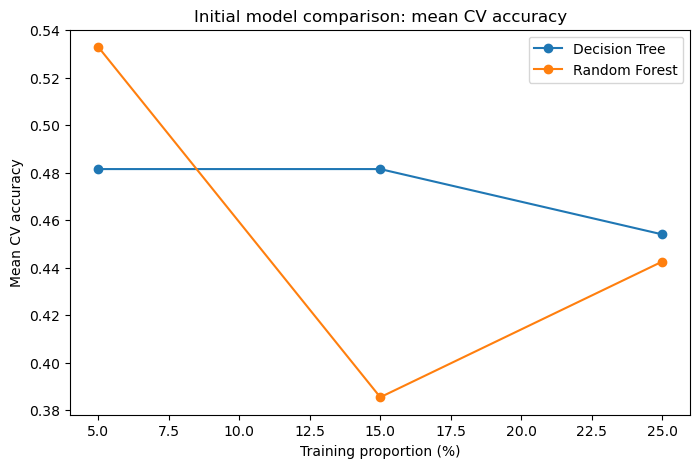

In [248]:
plt.figure(figsize=(8, 5))

plt.plot([5,15,25], [dt_cv_5.mean(), dt_cv_15.mean(), dt_cv_25.mean()], marker="o", label="Decision Tree")

plt.plot([5,15,25], [rf_cv_5.mean(), rf_cv_15.mean(), rf_cv_25.mean()], marker="o", label="Random Forest")

plt.title("Initial model comparison: mean CV accuracy")
plt.xlabel("Training proportion (%)")
plt.ylabel("Mean CV accuracy")
plt.legend()
plt.show()

In [249]:
from sklearn.model_selection import GridSearchCV

In [251]:
dt_param_grid = {"max_depth": [2,4,6,8, None]}

In [252]:
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_param_grid, cv=3, scoring="accuracy")

dt_grid.fit(X_train_25, y_train_25)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [2, 4, 6, 8, None]}, scoring='accuracy')

In [253]:
print("Best parameters:", dt_grid.best_params_)
print("Best mean CV accuracy:", dt_grid.best_score_)
print("Training accuracy:", dt_grid.score(X_train_25, y_train_25))
print("Testing accuracy:", dt_grid.score(X_test_25, y_test_25))

Best parameters: {'max_depth': 2}
Best mean CV accuracy: 0.5114942528735632
Training accuracy: 0.5459770114942529
Testing accuracy: 0.5153256704980843


In [254]:
rf_param_grid = {"n_estimators": [25, 50, 100, 200], "max_depth": [2,4, None]}

In [256]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid, cv=3, scoring="accuracy")

rf_grid.fit(X_train_25, y_train_25)

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [2, 4, None],
                         'n_estimators': [25, 50, 100, 200]},
             scoring='accuracy')

In [257]:
print("Best parameters:", rf_grid.best_params_)
print("Best mean CV accuracy:", rf_grid.best_score_)
print("Training accuracy:", rf_grid.score(X_train_25, y_train_25))
print("Testing accuracy:", rf_grid.score(X_test_25, y_test_25))

Best parameters: {'max_depth': 2, 'n_estimators': 50}
Best mean CV accuracy: 0.5229885057471265
Training accuracy: 0.5344827586206896
Testing accuracy: 0.5268199233716475


In [258]:
dt_tuned_pred = dt_grid.predict(X_test_25)
rf_tuned_pred = rf_grid.predict(X_test_25)

In [259]:
from sklearn.metrics import classification_report

In [260]:
print("Tuned Decision Tree")
print(classification_report(y_test_25, dt_tuned_pred))

print("Tuned Decision Tree")
print(classification_report(y_test_25, rf_tuned_pred))


Tuned Decision Tree
              precision    recall  f1-score   support

           1       0.27      0.04      0.07        95
           2       0.52      0.97      0.68       272
           3       0.00      0.00      0.00       155

    accuracy                           0.52       522
   macro avg       0.26      0.34      0.25       522
weighted avg       0.32      0.52      0.37       522

Tuned Decision Tree
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        95
           2       0.53      1.00      0.69       272
           3       0.75      0.02      0.04       155

    accuracy                           0.53       522
   macro avg       0.43      0.34      0.24       522
weighted avg       0.50      0.53      0.37       522



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-pa

In [262]:
from sklearn.metrics import confusion_matrix

In [266]:
dt_cm = confusion_matrix(y_test_25, dt_tuned_pred, labels=[1,2,3])

In [270]:
plt.figure(figsize = 6, 4) sns.heatmap(dt_cm, annot=True, fmt="d", cmap="Blues", xticklabels=[1,2,3], yticklabels=[1,2,3])

plt.title("Tuned Decision Tree: confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual")

SyntaxError: positional argument follows keyword argument (3750236712.py, line 1)